# 📘 Time Series Analysis with Pandas (Teaching Material)

## 1️⃣ Import Libraries & Load Dataset



In [22]:
# Import required libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [23]:
# Load dataset
df = sns.load_dataset('flights')

# View first few rows
df.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


👉 Dataset info:

* `year`: Year
* `month`: Month
* `passengers`: Number of airline passengers


In [ ]:
## 2️ Convert to Proper Time Series Format


In [24]:
# 1) Combine year and month into a datetime column
df['date'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str))
df.head()

C:\Users\hi\AppData\Local\Temp\ipykernel_17860\3204249459.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['date'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str))


,year,month,passengers,date
0,1949,Jan,112,1949-01-01
1,1949,Feb,118,1949-02-01
2,1949,Mar,132,1949-03-01
3,1949,Apr,129,1949-04-01
4,1949,May,121,1949-05-01


In [25]:
# 2) Set as index
df.set_index('date', inplace=True)
df.head()

,year,month,passengers
date,,,
1949-01-01,1949,Jan,112
1949-02-01,1949,Feb,118
1949-03-01,1949,Mar,132
1949-04-01,1949,Apr,129
1949-05-01,1949,May,121


In [26]:
# 3) Drop unnecessary columns
df.drop(['year', 'month'], axis=1, inplace=True)

df.head()


,passengers
date,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


👉 Important concept:

* Time series in pandas = **Datetime index**


## 3️ Basic Time Series Plot


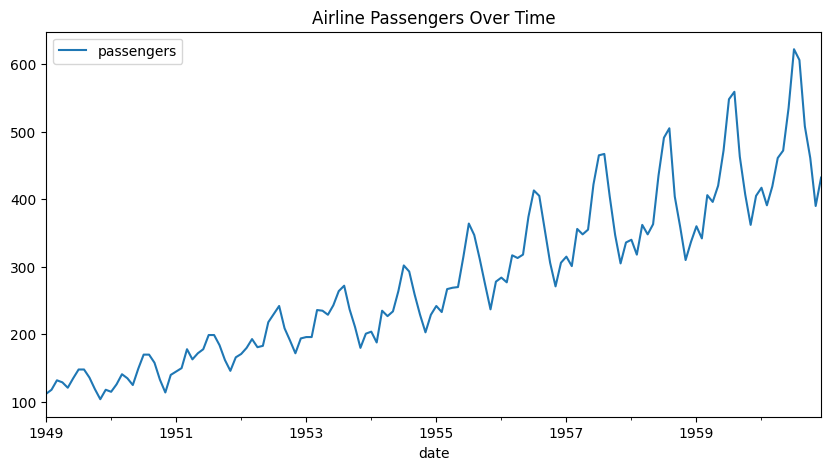

In [12]:
df.plot(figsize=(10,5), title="Airline Passengers Over Time")
plt.show()

In [ ]:
👉 Observation:

* Trend (overall increase)
* Seasonality (repeating yearly pattern)


## 4️ Resampling (Change Time Frequency)


In [13]:
# 1) Yearly average passengers
yearly = df.resample('Y').mean()
yearly

C:\Users\hi\AppData\Local\Temp\ipykernel_21184\2360872913.py:2: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  yearly = df.resample('Y').mean()


,passengers
date,
1949-12-31,126.666667
1950-12-31,139.666667
1951-12-31,170.166667
1952-12-31,197.000000
1953-12-31,225.000000
1954-12-31,238.916667
1955-12-31,284.000000
1956-12-31,328.250000
1957-12-31,368.416667


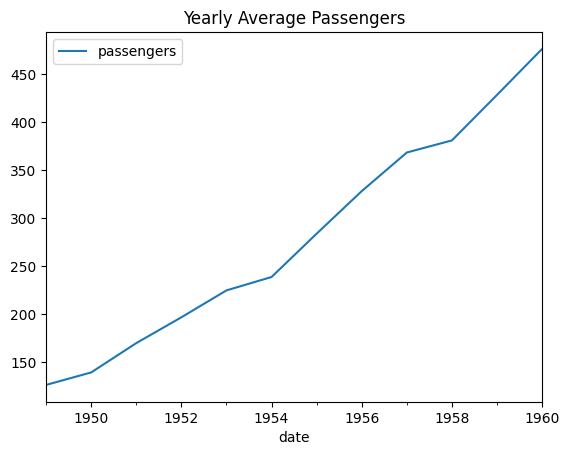

In [14]:
# 2) Now plot it

yearly.plot(title="Yearly Average Passengers")
plt.show()


In [ ]:
👉 Key points:

* `'M'` → Monthly
* `'Y'` → Yearly
* `'W'` → Weekly


## 5️ Rolling Statistics (Moving Average)

In [8]:
# 1) Rolling mean (12 months)
df['rolling_mean'] = df['passengers'].rolling(window=12).mean()
df.head(13)

,passengers,rolling_mean
date,,
1949-01-01,112,NaN
1949-02-01,118,NaN
1949-03-01,132,NaN
1949-04-01,129,NaN
1949-05-01,121,NaN
1949-06-01,135,NaN
1949-07-01,148,NaN
1949-08-01,148,NaN
1949-09-01,136,NaN


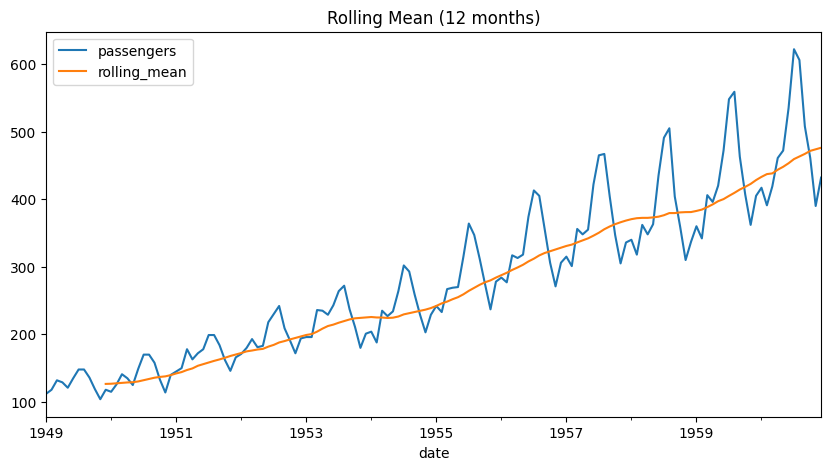

In [12]:
# 2) 
df.plot(figsize=(10,5), title="Rolling Mean (12 months)")
plt.show()

👉 Observation:

* Smooths noise
* Highlights trend


In [16]:
# drop the column rolling mean
df.drop('rolling_mean', axis=1, inplace=True)
df

,passengers
date,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
...,...
1960-08-01,606
1960-09-01,508
1960-10-01,461


## 6️ Handling Missing Dates

In [17]:
# 1) Create missing values artificially
df_missing = df.copy()
df_missing.iloc[5:10] = None
df_missing.head(15)

,passengers
date,
1949-01-01,112.0
1949-02-01,118.0
1949-03-01,132.0
1949-04-01,129.0
1949-05-01,121.0
1949-06-01,NaN
1949-07-01,NaN
1949-08-01,NaN
1949-09-01,NaN


In [18]:
# 2) Fill missing values: ffill, bfill
df_missing['ffilled'] = df_missing['passengers'].fillna(method='ffill')
df_missing['bfilled'] = df_missing['passengers'].fillna(method='bfill')

df_missing.head(15)

C:\Users\hi\AppData\Local\Temp\ipykernel_17860\4099180508.py:2: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_missing['ffilled'] = df_missing['passengers'].fillna(method='ffill')
C:\Users\hi\AppData\Local\Temp\ipykernel_17860\4099180508.py:3: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_missing['bfilled'] = df_missing['passengers'].fillna(method='bfill')


,passengers,ffilled,bfilled
date,,,
1949-01-01,112.0,112.0,112.0
1949-02-01,118.0,118.0,118.0
1949-03-01,132.0,132.0,132.0
1949-04-01,129.0,129.0,129.0
1949-05-01,121.0,121.0,121.0
1949-06-01,NaN,121.0,104.0
1949-07-01,NaN,121.0,104.0
1949-08-01,NaN,121.0,104.0
1949-09-01,NaN,121.0,104.0


👉 Observation:

* `ffill` (forward fill)
* `bfill` (backward fill)


## 7️ Time-Based Filtering

In [27]:
df

,passengers
date,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
...,...
1960-08-01,606
1960-09-01,508
1960-10-01,461


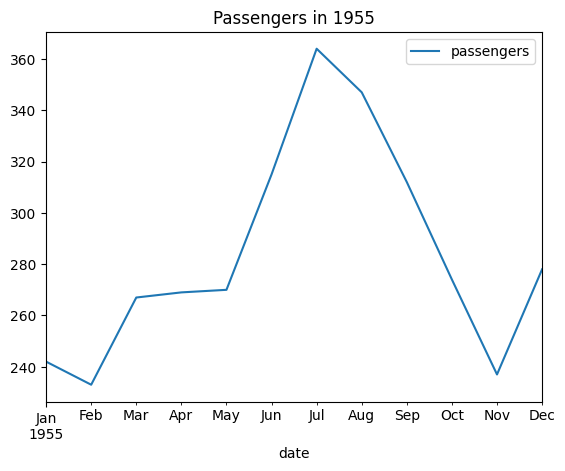

In [29]:
# Select data from a specific year

# Select data for 1955
df_1955 = df.loc['1955']

df_1955.plot(title="Passengers in 1955")
plt.show()

👉 Observation:

* Easy slicing using dates


## 8️ Decomposition (Trend + Seasonality)

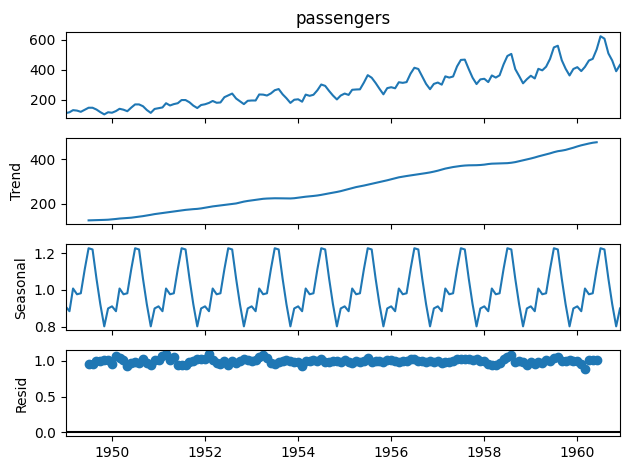

In [30]:
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(df['passengers'], model='multiplicative')

result.plot()
plt.show()


In [ ]:
👉 Observation:

* Trend
* Seasonality
* Residual (noise)


In [ ]:
## 9️ Lag Features (Important for ML)

In [32]:
# Create lag features
df['lag_1'] = df['passengers'].shift(1)
df['lag_12'] = df['passengers'].shift(12)

df.head(15)


,passengers,lag_1,lag_12
date,,,
1949-01-01,112,NaN,NaN
1949-02-01,118,112.0,NaN
1949-03-01,132,118.0,NaN
1949-04-01,129,132.0,NaN
1949-05-01,121,129.0,NaN
1949-06-01,135,121.0,NaN
1949-07-01,148,135.0,NaN
1949-08-01,148,148.0,NaN
1949-09-01,136,148.0,NaN


In [ ]:
👉 Observation:

* Used in forecasting models
* Helps capture past dependency

## 🔟 Simple Forecasting (Bonus Intro)

In [33]:

from statsmodels.tsa.arima.model import ARIMA

# Fit model
model = ARIMA(df['passengers'], order=(1,1,1))
model_fit = model.fit()

# Forecast next 12 steps
forecast = model_fit.forecast(steps=12)

print(forecast)


1961-01-01    475.735059
1961-02-01    454.996073
1961-03-01    464.830415
1961-04-01    460.167010
1961-05-01    462.378378
1961-06-01    461.329756
1961-07-01    461.827008
1961-08-01    461.591213
1961-09-01    461.703026
1961-10-01    461.650005
1961-11-01    461.675148
1961-12-01    461.663225
Freq: MS, Name: predicted_mean, dtype: float64


c:\Users\hi\Desktop\projects\python_projects\tutorial\tut_tensorflow\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\hi\Desktop\projects\python_projects\tutorial\tut_tensorflow\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\hi\Desktop\projects\python_projects\tutorial\tut_tensorflow\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
